# David 2012: calibración química y validación independiente

Se conservan las ecuaciones (3) y la extensión de la sección III-A: X, Nx, Ntr, Tr, S, E y CO₂ acumulado; crecimiento Contois; síntesis de transportadores; dos contribuciones fermentativas originales y una adicional tras nutrición; incorporación del nitrógeno distribuida en el tiempo. No se utiliza cinética de Zenteno, mortalidad añadida, transferencia de gas, activación por azúcar, ganancia del sensor ni transitorio histórico.

**No es una reproducción numérica del código de los autores.** Las funciones no publicadas se reconstruyen con autorización del usuario: interpolación lineal entre extremos 18–30 °C de la tabla I, con amplitudes calibradas; parámetros nutricionales lineales entre avance 0 y 1; reparto inicial Nx/N mediante dos fracciones interpoladas entre N₀=0.071 y 0.57 g/L. Se mantienen los extremos fuera de intervalo, sin extrapolación. Esta parametrización es una reconstrucción empírica, no una ecuación adicional tomada de otro modelo. Los resultados fuera de 18–30 °C y las funciones débilmente identificadas deben interpretarse con cautela.

## Ecuaciones implementadas
\[
\dot X=\mu_{max}(T)\frac{N_x}{K_xX+N_x}X,\qquad
\dot{Tr}=\eta_{max}(T)\frac{N_{tr}}{K_{tr}+N_{tr}}X.
\]
Sin nutrición posterior:
\[
\dot E=\dot{CO}_2=\left[\beta_{max,1}(T)\frac{N_x}{K_xX+N_x}+\beta_{max,2}(T)\frac{K_E(T)}{K_E(T)+E}\right]\frac{S}{K_S(T)+S}X(1+\varphi(T)Tr).
\]
Desde la nutrición se añade dentro del corchete $\beta_{max,3}N_{tr}/(K_{tr}+N_{tr})$ y se utiliza $\varphi_2$ en lugar de $\varphi(T)$. La fracción $\alpha$, el intervalo $t_{rise}$ y esos dos coeficientes dependen del avance $[S(0)-S(t_{add})]/S(0)$, calculado con la trayectoria predicha, nunca con mediciones de validación.
\[
\dot N_x=-k_1\dot X+\alpha u_N,\quad
\dot N_{tr}=-k'_1\dot{Tr}+(1-\alpha)u_N,\quad
\dot S=-k_2\dot E.
\]
$u_N=N_{add}/t_{rise}$ durante el intervalo de incorporación y cero después. $k'_1=0.16$, $k_2=2.17$ fijos; rendimiento E/S=0.46083 menor que 0.5114. Tr(0)=0 significa exceso de transportadores inicialmente nulo. El etanol inicial medido se conserva: CO₂ representa sólo producción nueva, de modo que CO₂(t)=E(t)-E(0).

## Política cerrada
- Ajuste: **sólo química depurada LAB004–009**, X, YAN, S=G+F medido y etanol, t>0. Ningún CO₂ entra al objetivo.
- Validación: química y CO₂ LAB019–021; ningún parámetro se ajusta a esos ensayos. No se excluye LAB006 al evaluar LAB020.
- Igual contribución por laboratorio y variable, errores divididos por escalas X=.25 g/L, N=.03 g/L, S=5 g/L, E=3 g/L; pesos X=N=2 y S=E=1. Son escalas de normalización, no incertidumbres instrumentales estimadas.
- Temperatura de logs; condiciones iniciales como entradas; se conservan muestras químicas numéricas NUT. LAB019–021: volumen remanente, muestra 1 descontada y sin aporte volumétrico de nutrición. La entrada nutricional distribuida representa la disponibilidad efectiva de David, no que la adición física haya durado horas.
- CO₂ observado: medianas horarias RAW convertidas por volumen remanente. No se filtra la predicción. Se informa RMSE completo y residuo censurado bajo 0.05; ningún punto determina el ajuste.
- Dos puntos iniciales y optimización acotada; no se afirma identificabilidad por el simple hecho de obtener un ajuste. Se muestran valores singulares, límites y variación entre inicios.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.david_2012 import kinetics as david
from wine_fermentation.models.david_2012.calibration import prepare,fit,COLUMNS
from wine_fermentation.models.david_2012.empirical import NAMES,START,BOUNDS
protected=[p for folder in ('src','configs') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and 'david_2012' not in str(p)]
def hashes():return {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
before=hashes()
tasks,training_data,profiles=prepare(ROOT)
display(pd.DataFrame([dict(lab=z['lab'],T_min=z['temp'].min(),T_max=z['temp'].max(),**{k:len(y) for k,(t,y) in z['support'].items()}) for z in tasks]))
display(pd.DataFrame(dict(parameter=NAMES,start=START,lower=[b[0] for b in BOUNDS],upper=[b[1] for b in BOUNDS])))


,lab,T_min,T_max,X,N,S,E
0,LAB004,17.799592,21.342214,10,12,12,4
1,LAB005,18.049978,21.407525,10,12,12,4
2,LAB006,16.099985,18.266753,12,14,14,4
3,LAB007,17.418578,21.022309,11,12,12,5
4,LAB008,17.381837,20.895778,11,12,12,5
5,LAB009,17.651161,21.655530,10,11,11,4


,parameter,start,lower,upper
0,mu_max,1.0000,0.1500,6.000
1,eta_max,1.0000,0.1500,6.000
2,beta_max_1,1.0000,0.1500,6.000
3,beta_max_2,1.0000,0.1500,6.000
4,KS,1.0000,0.1500,6.000
5,KE,1.0000,0.1500,6.000
6,phi,1.0000,0.1500,6.000
7,Kx,0.0127,0.0010,0.500
8,k1,0.0528,0.0100,0.200
9,Ktr,0.3134,0.0100,2.000


In [2]:
parameters,result=fit(tasks,max_nfev=45)
folder=ROOT/'configs/models/david_2012';folder.mkdir(exist_ok=True)
(folder/'fit.json').write_text(json.dumps(result,indent=2)+'\n',encoding='utf-8')
display(pd.Series({k:result[k] for k in ('success','message','initial_objective','objective','calls','active_bounds','singular_values')}))
display(pd.Series(result['parameters'],name='Fitted parameters'))
train_curves={z['lab']:david.simulate(z['time'],z['temp'],z['initial'],z['events'],parameters) for z in tasks}


Start 1 objective 27.542044684182418 success True nfev 22


Start 2 objective 28.372737460969873 success True nfev 21


success                                                           True
message                     `ftol` termination condition is satisfied.
initial_objective                                          1260.617673
objective                                                    27.542045
calls                                                              804
active_bounds                      [rise_0, alpha_0, alpha_1, beta3_1]
singular_values      [41.358744888562214, 13.639267644631808, 11.85...
dtype: object

mu_max              2.383782
eta_max             0.353514
beta_max_1          5.984061
beta_max_2          0.459958
KS                  0.168124
KE                  3.237429
phi                 4.598745
Kx                  0.292645
k1                  0.027492
Ktr                 0.031059
nx_fraction_071     0.162976
nx_fraction_570     0.289081
rise_0              0.513667
rise_1             20.645687
alpha_0             0.001006
alpha_1             0.001027
beta3_0             0.586892
beta3_1             0.000823
phi2_0              0.752287
phi2_1              0.388843
Name: Fitted parameters, dtype: float64

In [3]:
from dataclasses import replace
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
v=load(ROOT)
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h'])
co2_observations=observations(raw)
validation={}
for lab in ['LAB019','LAB020','LAB021']:
 b=v.batches[lab];ev=raw[(raw.lab==lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h')
 et=ev.time_h.to_numpy();vol=ev.remaining_volume_L.to_numpy()
 def volume(t):return np.r_[2.,vol][np.searchsorted(et,np.asarray(t),side='right')]
 initial=dict(X=b.initials['X'],N=b.initials['N'],S=b.initials['G']+b.initials['F'],E=b.initials['E'])
 s=chemical_observations(v.chem,lab,'GF');s0=s[s.t_h.le(0)]
 if len(s0):initial['S']=float(s0.GF_g_l.iloc[-1])
 events=tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])
 validation[lab]=david.simulate(b.time,b.temperature_c,initial,events,parameters)
print('LAB019–021 leídos después del ajuste. Predicciones sin reajuste.')


LAB019–021 leídos después del ajuste. Predicciones sin reajuste.


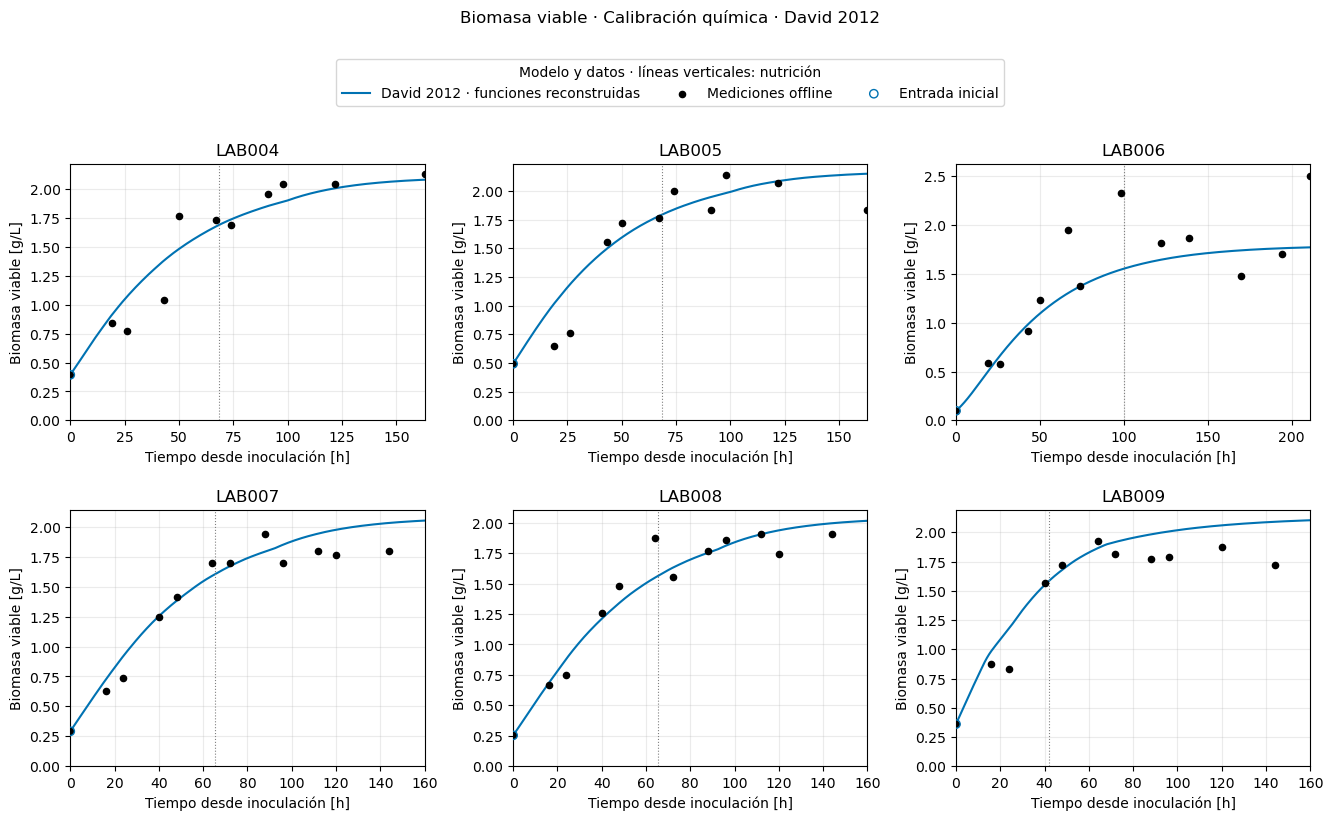

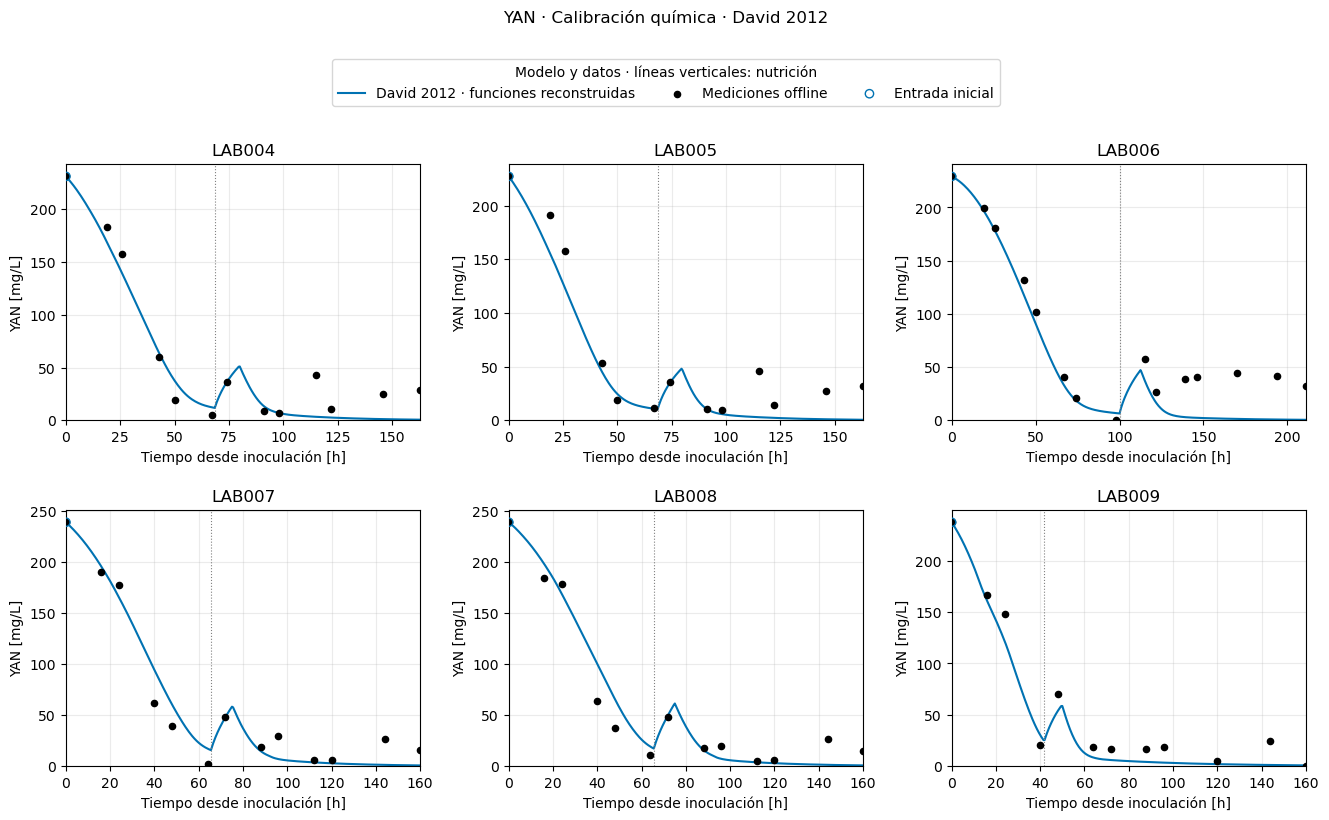

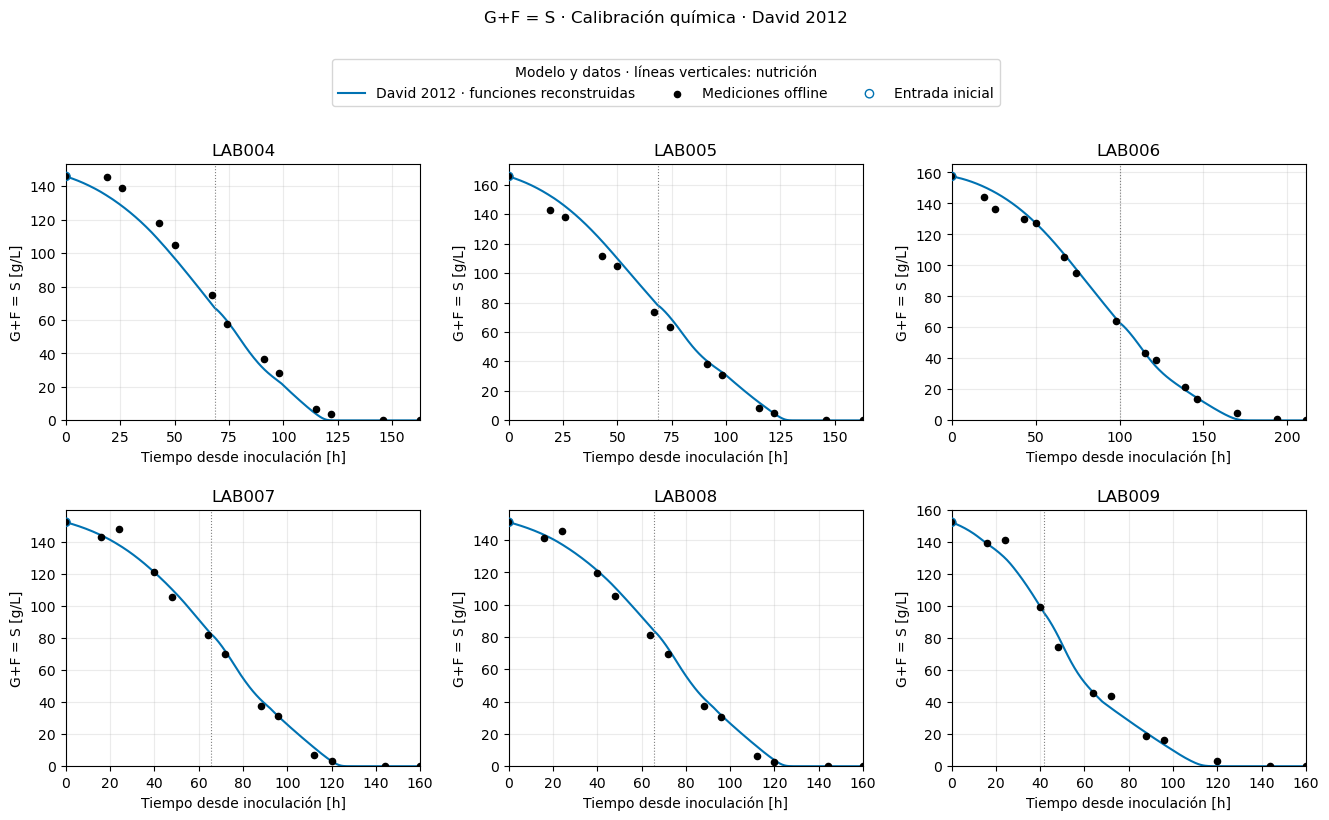

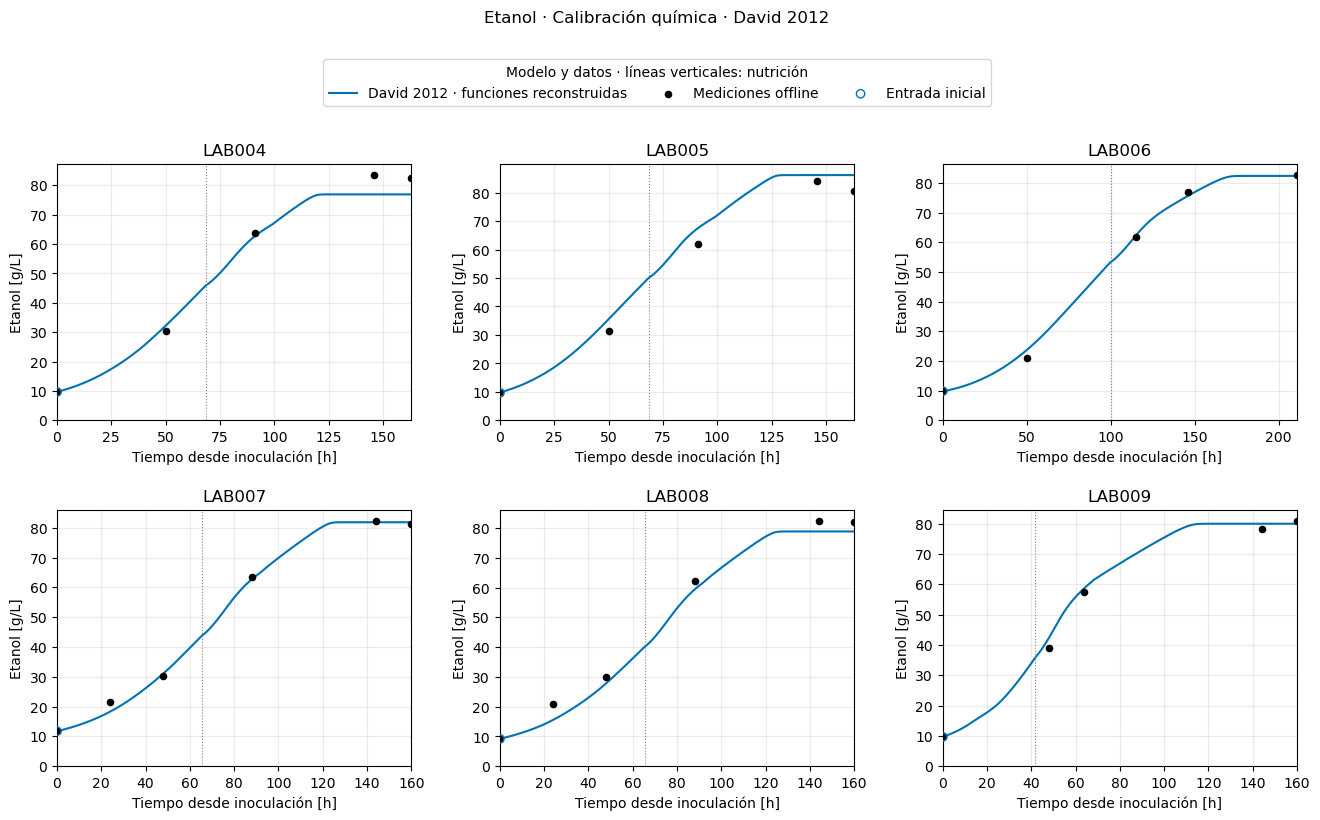

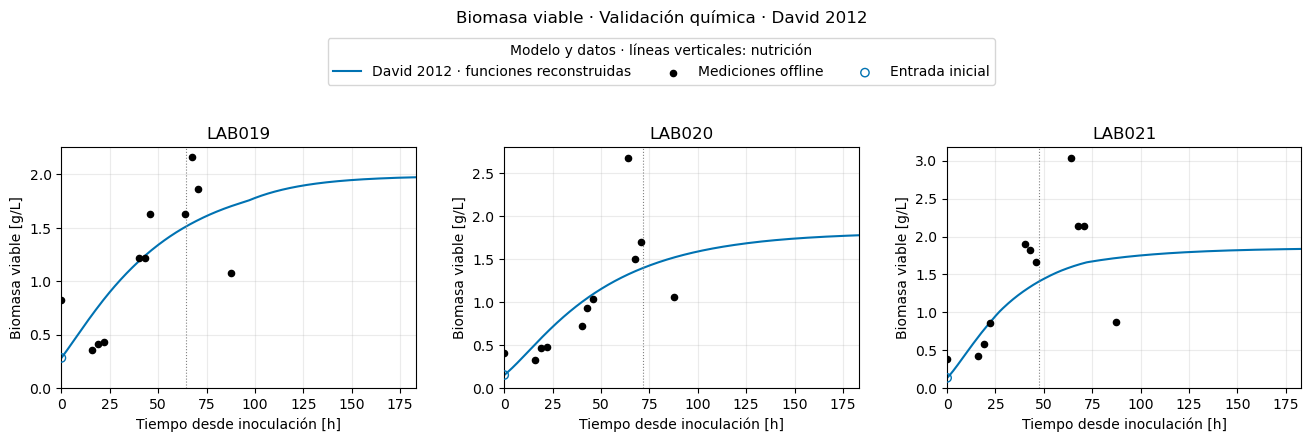

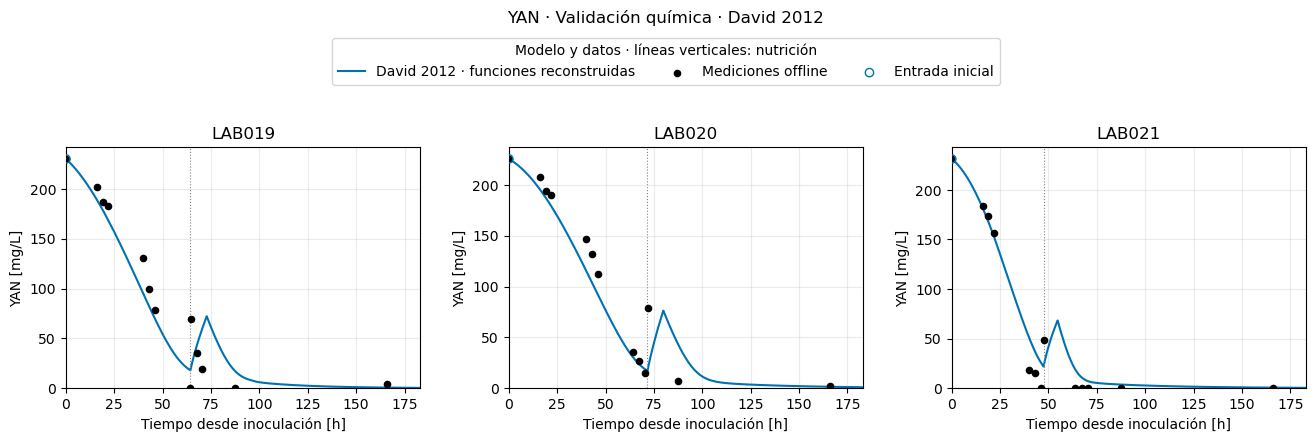

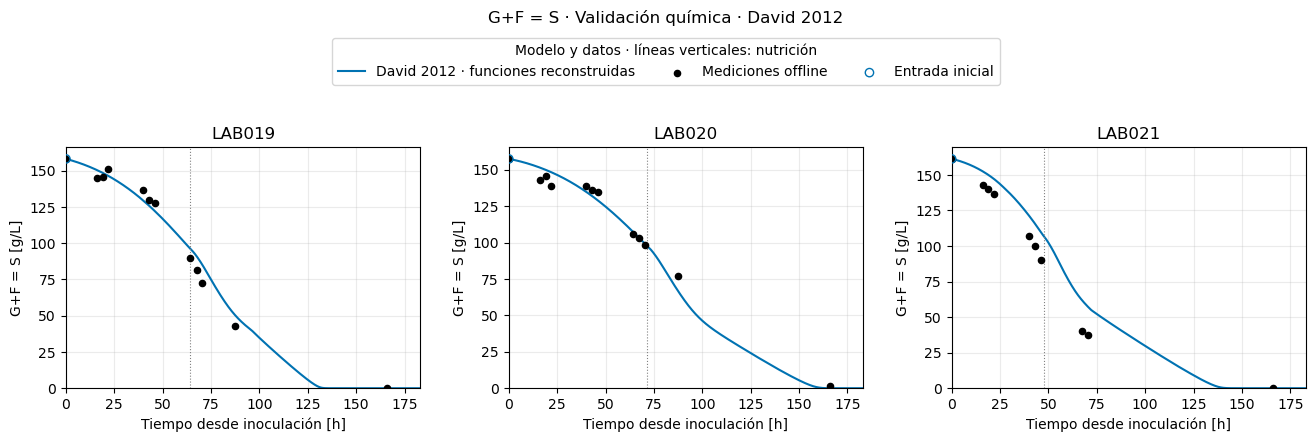

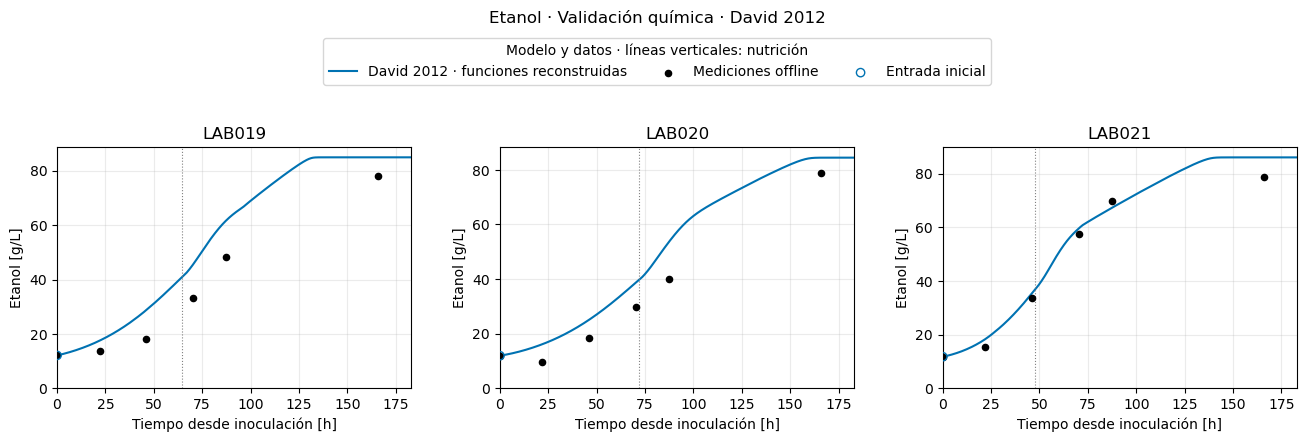

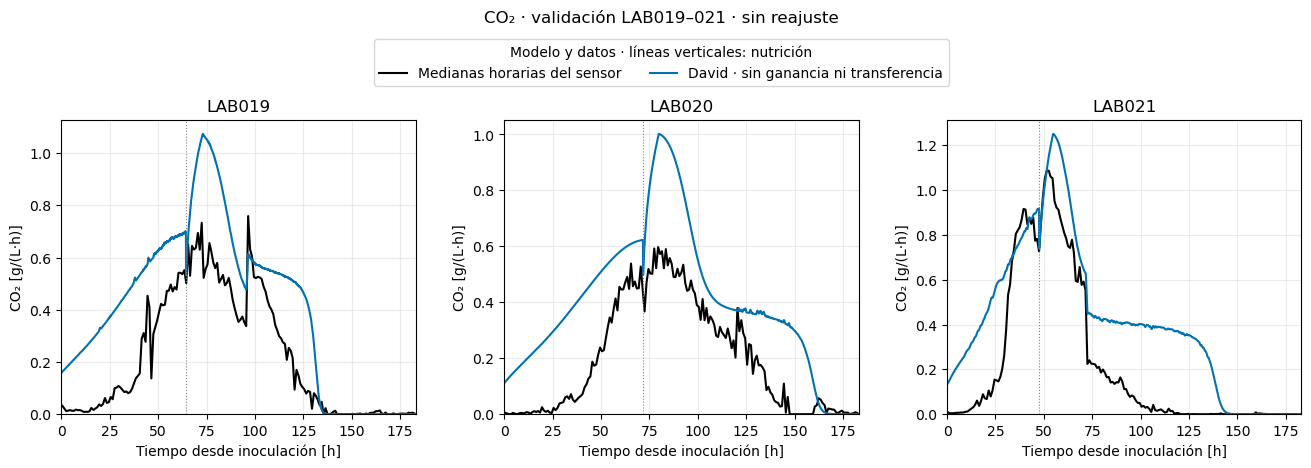

,split,lab,variable,unit,n,RMSE,bias,censored_RMSE
0,Calibración química,LAB004,X,g/L,10,0.18125,0.00657,NaN
1,Calibración química,LAB005,X,g/L,10,0.22326,0.07510,NaN
2,Calibración química,LAB006,X,g/L,12,0.38106,-0.18815,NaN
3,Calibración química,LAB007,X,g/L,11,0.14332,0.06500,NaN
4,Calibración química,LAB008,X,g/L,11,0.13457,-0.00585,NaN
5,Calibración química,LAB009,X,g/L,10,0.20293,0.14182,NaN
6,Calibración química,LAB004,N,mg/L,12,18.21404,-8.25140,NaN
7,Calibración química,LAB005,N,mg/L,12,22.99199,-16.11647,NaN
8,Calibración química,LAB006,N,mg/L,14,24.33489,-18.16694,NaN
9,Calibración química,LAB007,N,mg/L,12,16.66790,-1.03029,NaN


Mayor singular / menor singular: 94200.3707645801
Parámetros en límites: ['rise_0', 'alpha_0', 'alpha_1', 'beta3_1']
Verificado: modelos anteriores intactos; ninguna muestra LAB019–021 ni CO₂ participó en calibración. No se exportaron CSV/PNG.


In [4]:
metrics=[]
specs=[('X','Biomasa viable','g/L',1.),('N','YAN','mg/L',1000.),('S','G+F = S','g/L',1.),('E','Etanol','g/L',1.)]
for group,curves,labs in [('Calibración química',train_curves,list(train_curves)),('Validación química',validation,list(validation))]:
 for state,title,unit,scale in specs:
  fig,axes=plt.subplots(int(np.ceil(len(labs)/3)),3,figsize=(16,4.3*int(np.ceil(len(labs)/3))),squeeze=False)
  for ax,lab in zip(axes.flat,labs):
   f=curves[lab]
   if group=='Calibración química':
    z=next(z for z in tasks if z['lab']==lab);o=training_data[training_data.batch.eq(lab)].dropna(subset=['time_h',COLUMNS[state]]);ot=o.time_h.to_numpy();oy=o[COLUMNS[state]].to_numpy();events=z['events']
   else:
    o=chemical_observations(v.chem,lab,'GF' if state=='S' else state);ot=o.t_h.to_numpy();oy=o[CHEMICAL_COLUMNS['GF' if state=='S' else state]].to_numpy();events=v.batches[lab].pulses['N']
   ax.plot(f.index,scale*f[state],label='David 2012 · funciones reconstruidas',color='#0072B2')
   ax.scatter(ot,scale*oy,color='black',s=20,label='Mediciones offline',zorder=4)
   ax.scatter([0],[scale*f[state].iloc[0]],facecolors='none',edgecolors='#0072B2',label='Entrada inicial',zorder=5)
   for ti,d in events:ax.axvline(ti,color='gray',ls=':',lw=.8)
   ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel=f'{title} [{unit}]',xlim=(min(0,float(ot.min())) if len(ot) else 0,f.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
   mask=(ot>0)&(ot<=f.index[-1]);error=scale*(np.interp(ot[mask],f.index,f[state])-oy[mask])
   metrics.append(dict(split=group,lab=lab,variable=state,unit=unit,n=len(error),RMSE=np.sqrt(np.mean(error**2)),bias=error.mean()))
  fig.suptitle(f'{title} · {group} · David 2012',y=.99)
  handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.94),ncol=3,title='Modelo y datos · líneas verticales: nutrición')
  fig.subplots_adjust(top=.67 if len(labs)==3 else .81,hspace=.35,wspace=.25);plt.show()
fig,axes=plt.subplots(1,3,figsize=(16,4.6))
for ax,(lab,f) in zip(axes,validation.items()):
 o=co2_observations[lab];o=o[o.time_h.between(0,f.index[-1])]
 pred=np.interp(o.time_h,f.index,f.qCO2);y=o.co2_raw_g_l_h.to_numpy();error=pred-y
 censored=np.where(y<.05,np.maximum(pred-.05,0),error)
 metrics.append(dict(split='Validación CO2',lab=lab,variable='CO2',unit='g/(L·h)',n=len(error),RMSE=np.sqrt(np.mean(error**2)),bias=error.mean(),censored_RMSE=np.sqrt(np.mean(censored**2))))
 ax.plot(o.time_h,y,color='black',label='Medianas horarias del sensor')
 ax.plot(f.index,f.qCO2,color='#0072B2',label='David · sin ganancia ni transferencia')
 for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
 ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(0,f.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
fig.suptitle('CO₂ · validación LAB019–021 · sin reajuste',y=.99)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.94),ncol=2,title='Modelo y datos · líneas verticales: nutrición')
fig.subplots_adjust(top=.75,wspace=.25);plt.show()
display(pd.DataFrame(metrics).round(5))
print('Mayor singular / menor singular:',result['singular_values'][0]/max(result['singular_values'][-1],1e-15))
print('Parámetros en límites:',result['active_bounds'])
assert hashes()==before,'Cambió un modelo/configuración anterior'
assert result['training_labs']==['LAB004','LAB005','LAB006','LAB007','LAB008','LAB009']
assert not result['CO2_in_objective']
print('Verificado: modelos anteriores intactos; ninguna muestra LAB019–021 ni CO₂ participó en calibración. No se exportaron CSV/PNG.')


## Resultados y alcance

Ambos puntos iniciales convergieron por criterio numérico: objetivos 27.5420 y 28.3727. Se seleccionó el menor. El objetivo inicial era 1260.6177. No es prueba de óptimo global ni de identificación física: la razón entre valores singulares es aproximadamente 94 200, y `rise_0`, `alpha_0`, `alpha_1` y `beta3_1` están cerca de límites. Las siete primeras cantidades guardadas en `parameters` son amplitudes adimensionales de funciones térmicas reconstruidas, no las tasas físicas a una temperatura concreta.

En holdout, RMSE de S: LAB019=6.859, LAB020=5.694 y LAB021=14.958 g/L. RMSE de etanol: 10.094, 8.790 y 3.883 g/L. RMSE de YAN: 24.10, 24.69 y 16.95 mg/L. RMSE de biomasa: 0.371, 0.482 y 0.637 g/L.

El CO₂ se predice sin ajustar a ninguna medición de gas: RMSE 0.2321, 0.2317 y 0.2412 g/(L·h). Arranca adelantado y sobreestima el caudal en los tres laboratorios. No se corrigieron el inicio, la amplitud ni la cola. Esta es una prueba de las ecuaciones de David con funciones empíricas reconstruidas desde la química disponible; no reproduce el ajuste original de los autores ni permite concluir que toda implementación de David fallaría igual.
